# 1. Análisis Exploratorio de Datos (EDA)
Exploración del dataset para encontrar relaciones entre variables, tendencias generales y conocer el tipo de variables con las que se está trabajando. 

### Imports y carga de datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../rendimiento_estudiantes.csv', sep=';')
print(f'Dataset cargado. {df.shape[0]} filas, {df.shape[1]} columnas')

print('Columnas:', df.columns)

Dataset cargado. 4424 filas, 37 columnas
Columnas: Index(['estado_civil', 'modo_solicitud', 'orden_solicitud', 'curso',
       'asistencia_diurna_vespertina', 'cualificacion_previa',
       'nota_cualificacion_previa', 'nacionalidad', 'cualificacion_madre',
       'cualificacion_padre', 'ocupacion_madre', 'ocupacion_padre',
       'nota_admision', 'desplazado', 'necesidades_educativas_especiales',
       'deudor', 'matricula_al_dia', 'genero', 'becado',
       'edad_al_matricularse', 'internacional',
       'asignaturas_1sem_convalidadas', 'asignaturas_1sem_matriculadas',
       'asignaturas_1sem_evaluadas', 'asignaturas_1sem_aprobadas',
       'nota_media_1sem', 'asignaturas_1sem_sin_evaluacion',
       'asignaturas_2sem_convalidadas', 'asignaturas_2sem_matriculadas',
       'asignaturas_2sem_evaluadas', 'asignaturas_2sem_aprobadas',
       'nota_media_2sem', 'asignaturas_2sem_sin_evaluacion', 'tasa_desempleo',
       'tasa_inflacion', 'pib', 'objetivo'],
      dtype='object')


### Visión general del dataset
Overview sobre todo el dataset, para ver qué variables hay, su tipo, y si hay valores nulos.

In [2]:
nulos = df.isnull().sum()
tipos = df.dtypes

print('Tipos de variable:')
print(df.dtypes.value_counts())

print('\nValores nulos por variable:')
print(nulos[nulos > 0] if nulos.any() else 'No hay valores nulos en el dataset.')

Tipos de variable:
object     18
int64      12
float64     7
Name: count, dtype: int64

Valores nulos por variable:
No hay valores nulos en el dataset.


> Hay un total de 19 variables numéricas (12 de ellas enteras) y 18 variables categóricas. Además, no hay valores nulos en todo el dataset, lo cual es bueno ya que no interferirán con las estadísticas.

### Distribución de la variable objetivo
Conteo de valores por cada clase de 'objetivo'. Con esto se determina si la variable está balanceada.

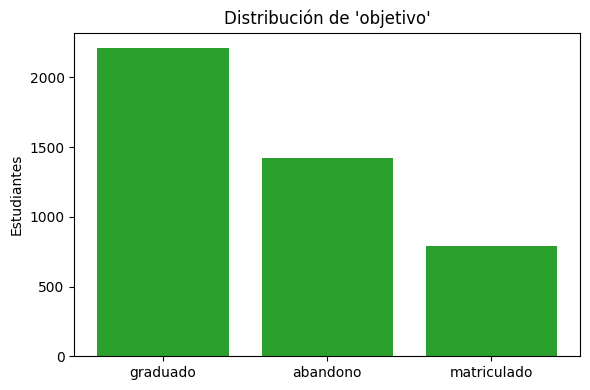

--- Porcentaje de cada clase de 'objetivo' ---
objetivo
graduado       49.93
abandono       32.12
matriculado    17.95
Name: proportion, dtype: float64


In [3]:
counts = df['objetivo'].value_counts()
pcts = df['objetivo'].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(counts.index, counts.values, color='tab:green')
ax.set_title('Distribución de \'objetivo\'')
ax.set_ylabel('Estudiantes')
plt.tight_layout()
plt.show()

print('--- Porcentaje de cada clase de \'objetivo\' ---')
print(pcts.round(2))

> El dataset no está balanceado, pero el desbalanceo es manejable. La categoría 'abandono' ocupa alrededor de 1/3 del dataset, mientras que para las otras dos, el ratio entre 'graduado' y 'matriculado' es casi de 3 a 1. Algo a tener en cuenta, pero no va a afectar drásticamente a los resultados.

### Estadísticos descriptivos de variables numéricas y relación con la variable objetivo
Se sacan métricas de las variables numéricas y se estudian algunas de las más importantes. Se estudia también la relación con el estado del estudiante en variables donde a priori puede haber relación.

In [4]:
num_cols = df.select_dtypes(include='number').columns.tolist()
df[num_cols].describe().round(2)

,orden_solicitud,nota_cualificacion_previa,nota_admision,edad_al_matricularse,asignaturas_1sem_convalidadas,asignaturas_1sem_matriculadas,asignaturas_1sem_evaluadas,asignaturas_1sem_aprobadas,nota_media_1sem,asignaturas_1sem_sin_evaluacion,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib
count,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00,4424.00
mean,1.73,132.61,126.98,23.27,0.71,6.27,8.30,4.71,10.64,0.14,0.54,6.23,8.06,4.44,10.23,0.15,11.57,1.23,0.00
std,1.31,13.19,14.48,7.59,2.36,2.48,4.18,3.09,4.84,0.69,1.92,2.20,3.95,3.01,5.21,0.75,2.66,1.38,2.27
min,0.00,95.00,95.00,17.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,7.60,-0.80,-4.06
25%,1.00,125.00,117.90,19.00,0.00,5.00,6.00,3.00,11.00,0.00,0.00,5.00,6.00,2.00,10.75,0.00,9.40,0.30,-1.70
50%,1.00,133.10,126.10,20.00,0.00,6.00,8.00,5.00,12.29,0.00,0.00,6.00,8.00,5.00,12.20,0.00,11.10,1.40,0.32
75%,2.00,140.00,134.80,25.00,0.00,7.00,10.00,6.00,13.40,0.00,0.00,7.00,10.00,6.00,13.33,0.00,13.90,2.60,1.79
max,9.00,190.00,190.00,70.00,20.00,26.00,45.00,26.00,18.88,12.00,19.00,23.00,33.00,20.00,18.57,12.00,16.20,3.70,3.51


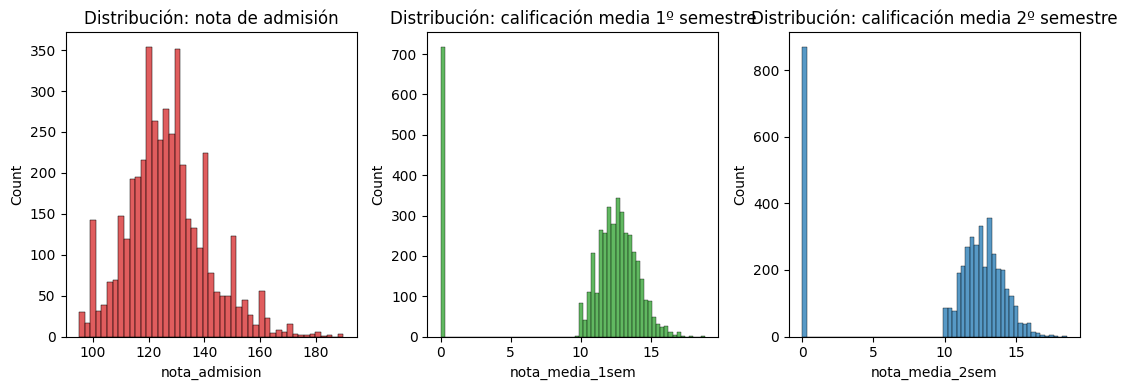

In [5]:
# Distribución de la nota de admisión
fig, axes = plt.subplots(1, 3, figsize=(11, 4))

sns.histplot(df['nota_admision'], ax=axes[0], color='tab:red')
axes[0].set_title('Distribución: nota de admisión')

sns.histplot(df['nota_media_1sem'], ax=axes[1], color='tab:green')
axes[1].set_title('Distribución: calificación media 1º semestre')

sns.histplot(df['nota_media_2sem'], ax=axes[2], color='tab:blue')
axes[2].set_title('Distribución: calificación media 2º semestre')

plt.tight_layout()
plt.show()

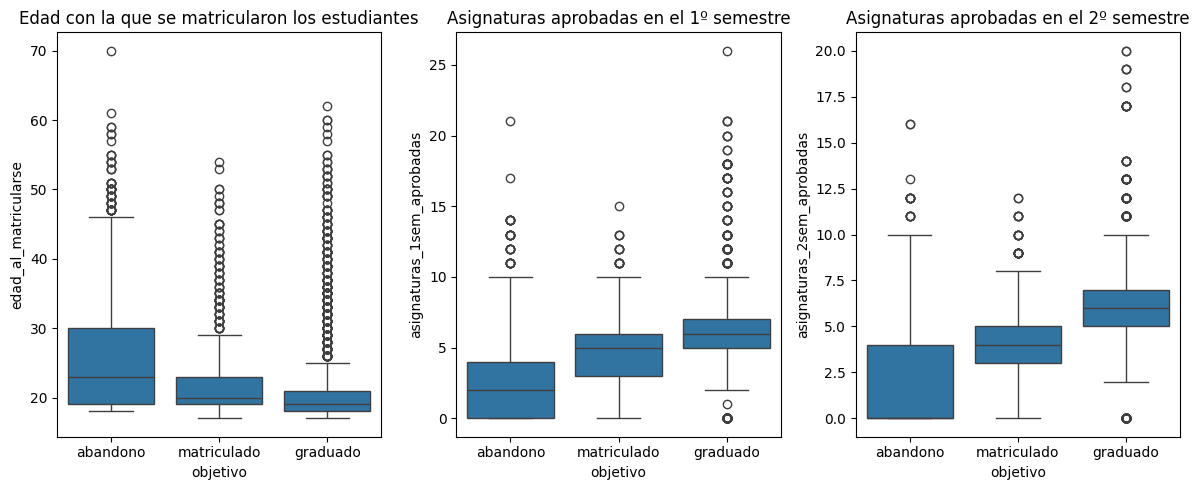

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

sns.boxplot(data=df, x='objetivo', y='edad_al_matricularse', ax=axes[0], order=['abandono', 'matriculado', 'graduado'])
axes[0].set_title('Edad con la que se matricularon los estudiantes')

sns.boxplot(data=df, x='objetivo', y='asignaturas_1sem_aprobadas', ax=axes[1], order=['abandono', 'matriculado', 'graduado'])
axes[1].set_title('Asignaturas aprobadas en el 1º semestre')

sns.boxplot(data=df, x='objetivo', y='asignaturas_2sem_aprobadas', ax=axes[2], order=['abandono', 'matriculado', 'graduado'])
axes[2].set_title('Asignaturas aprobadas en el 2º semestre')

plt.tight_layout()
plt.show()

> Se sacan valores importantes como que la nota de admisión media es 127 o que las notas del 1º y 2º semestre están distribuidas de forma muy similar. Respecto a la variable objetivo, se destacan relaciones importantes. La mayoría de personas que se gradúan están cerca de los 20 años, y los graduados tienden a aprobar más asignaturas que los que abandonan, aunque se ven casos inusuales de graduados con 0 asignaturas aprobadas.

### Mapa de correlaciones
Mapa de calor con las correlaciones entre todas las variables.

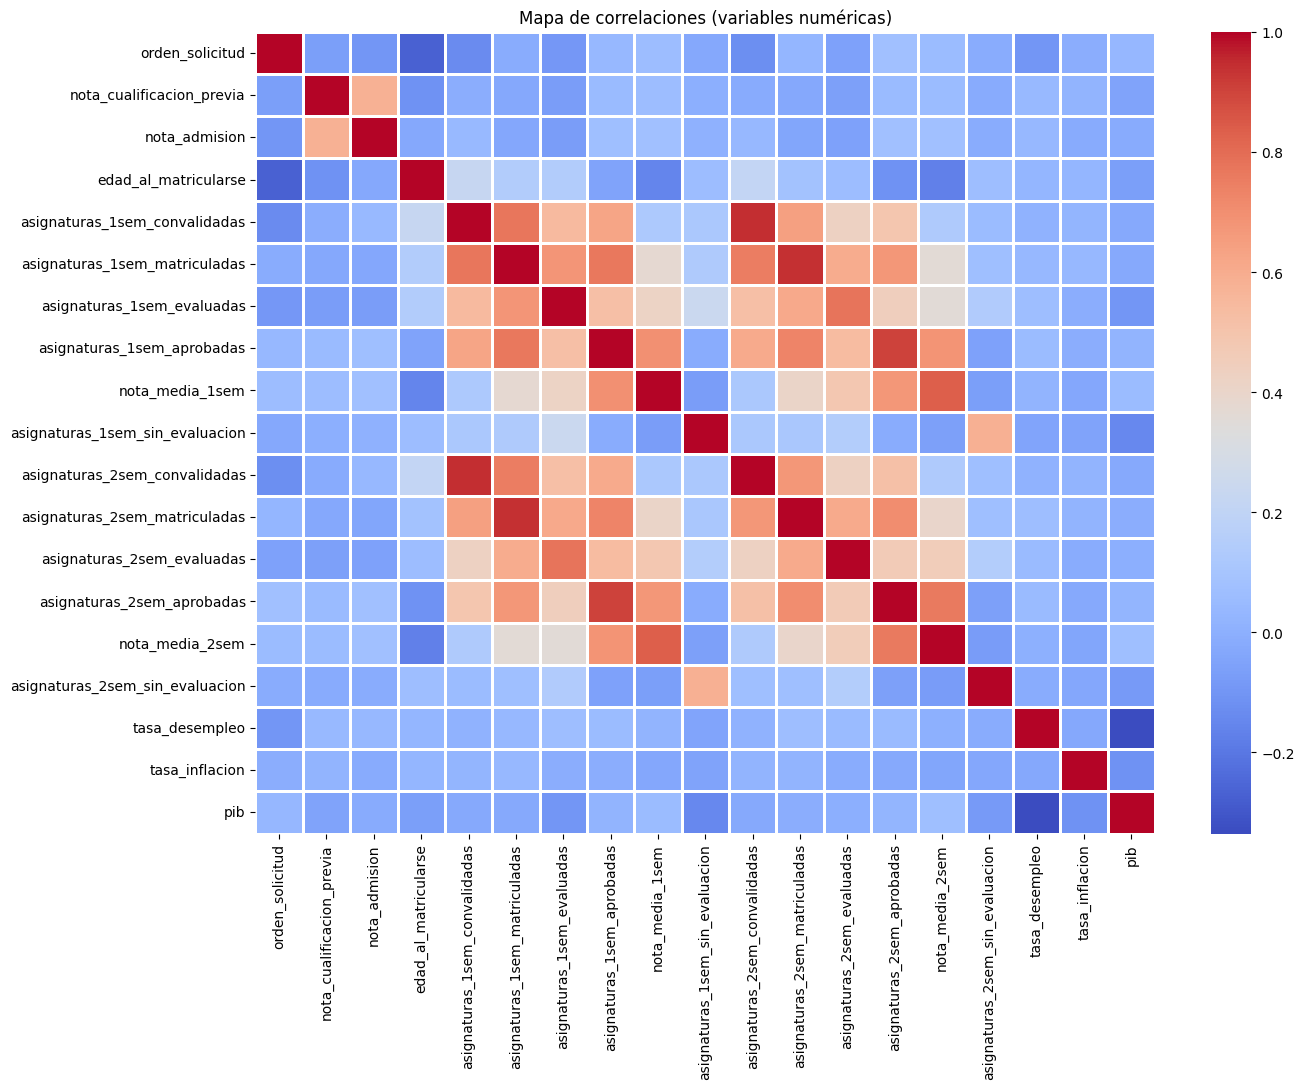

In [7]:
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr, cmap='coolwarm', linewidths=0.8, annot=False)
ax.set_title('Mapa de correlaciones (variables numéricas)')
plt.tight_layout()
plt.show()

> De este mapa se destaca la relación fuerte entre las variables 1sem y 2sem. Un estudiante tiende a repetir las mismas asignaturas convalidadas, matriculadas, evaluadas, aprobadas y su nota media de un semestre al siguiente. Estas variables también se relacionan unas con otras.